# Task 3 — Predictive Customer Churn Classifier (Random Forest & XGBoost)
**Datheon Machine Learning & Data Science Internship · Difficulty: intermediate**

**Goal.** Predict whether a telecom customer will leave (`Churn = 1`) or stay (`Churn = 0`), handle the class imbalance honestly, and evaluate with ROC-AUC (task-pack target: **> 0.80**).

| Item | Detail |
|---|---|
| Dataset | IBM Telco Customer Churn (7,043 customers, 21 columns) — `data/Telco-Customer-Churn.csv` |
| Models | Random Forest and XGBoost (+ Random Forest with SMOTE as an imbalance comparison) |
| Imbalance | Class weights (`class_weight`, `scale_pos_weight`) and SMOTE **inside the training pipeline only** |
| Validation | Stratified 5-fold cross-validation + `RandomizedSearchCV` hyper-parameter tuning on the training set |
| Metrics | Accuracy, precision, recall, F1, ROC-AUC, confusion matrix, feature importance |

> The ROC-AUC target is a goal, not a guarantee. All numbers below are produced by this notebook on a held-out test set that was never used for tuning or model selection.

## 1. Import libraries

In [1]:
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent                      # repository root (notebook is run from its own task folder)
sys.path.insert(0, str(ROOT / "src"))         # makes the shared `datheon_ml` helpers importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_recall_curve)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from datheon_ml.churn import (TARGET, load_raw, clean_telco, add_features, build_preprocessor,
                              split_columns, predict_churn)

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
DATA_PATH, RESULTS, MODELS = Path("data/Telco-Customer-Churn.csv"), Path("results"), Path("models")
RESULTS.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
print("Libraries imported.")

Libraries imported.


## 2. Load the dataset

In [2]:
raw = load_raw(DATA_PATH)
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data inspection

In [3]:
print("Shape:", raw.shape)
raw.info()

Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   s

In [4]:
display(raw.describe().round(2))
print("Churn counts (raw):"); display(raw["Churn"].value_counts())

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


Churn counts (raw):


Churn
No     5174
Yes    1869
Name: count, dtype: int64

## 4–5. Data cleaning — including `TotalCharges`
`TotalCharges` is stored as text because some cells contain a blank space. Converting it to numbers and checking the blanks is the key cleaning step of this task.

In [5]:
blank = raw["TotalCharges"].str.strip().eq("")
print("Blank TotalCharges values:", int(blank.sum()))
print("Their tenure values:", raw.loc[blank, "tenure"].unique())
print("Missing values in other columns:", int(raw.drop(columns="TotalCharges").isna().sum().sum()))
print("Duplicate customer IDs:", int(raw["customerID"].duplicated().sum()))

Blank TotalCharges values: 11
Their tenure values: [0]
Missing values in other columns: 0
Duplicate customer IDs: 0


All blank `TotalCharges` rows belong to customers with `tenure = 0` (new customers who have not been billed yet), so a value of **0.0** is the logically correct fill — this is a documented decision, not a guess.

In [6]:
df = clean_telco(raw)
print("Rows before:", len(raw), "| after cleaning:", len(df))
print("TotalCharges dtype:", df["TotalCharges"].dtype, "| NaNs:", int(df["TotalCharges"].isna().sum()))
df.head()

Rows before: 7043 | after cleaning: 7021
TotalCharges dtype: float64 | NaNs: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 6–7. Exploratory analysis and visualisation

Stay: 5164 (73.6%) | Churn: 1857 (26.4%)  -> imbalance ratio 2.78:1


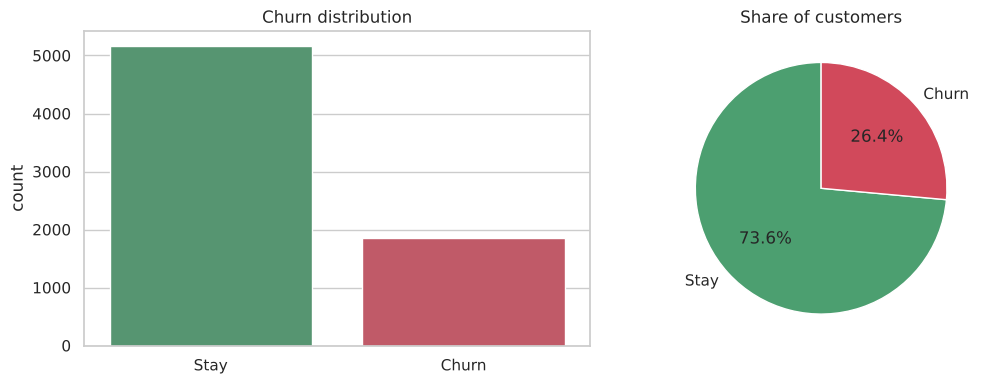

In [7]:
counts = df[TARGET].value_counts().sort_index()
rate = df[TARGET].mean()
print(f"Stay: {counts[0]} ({1-rate:.1%}) | Churn: {counts[1]} ({rate:.1%})  -> imbalance ratio {counts[0]/counts[1]:.2f}:1")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=df[TARGET].map({0: "Stay", 1: "Churn"}), hue=df[TARGET].map({0: "Stay", 1: "Churn"}),
              palette=["#4C9F70", "#D1495B"], legend=False, ax=ax[0])
ax[0].set_title("Churn distribution"); ax[0].set_xlabel("")
ax[1].pie(counts.values, labels=["Stay", "Churn"], autopct="%1.1f%%", colors=["#4C9F70", "#D1495B"], startangle=90)
ax[1].set_title("Share of customers")
plt.tight_layout(); plt.savefig(RESULTS / "churn_distribution.png", dpi=150); plt.show()

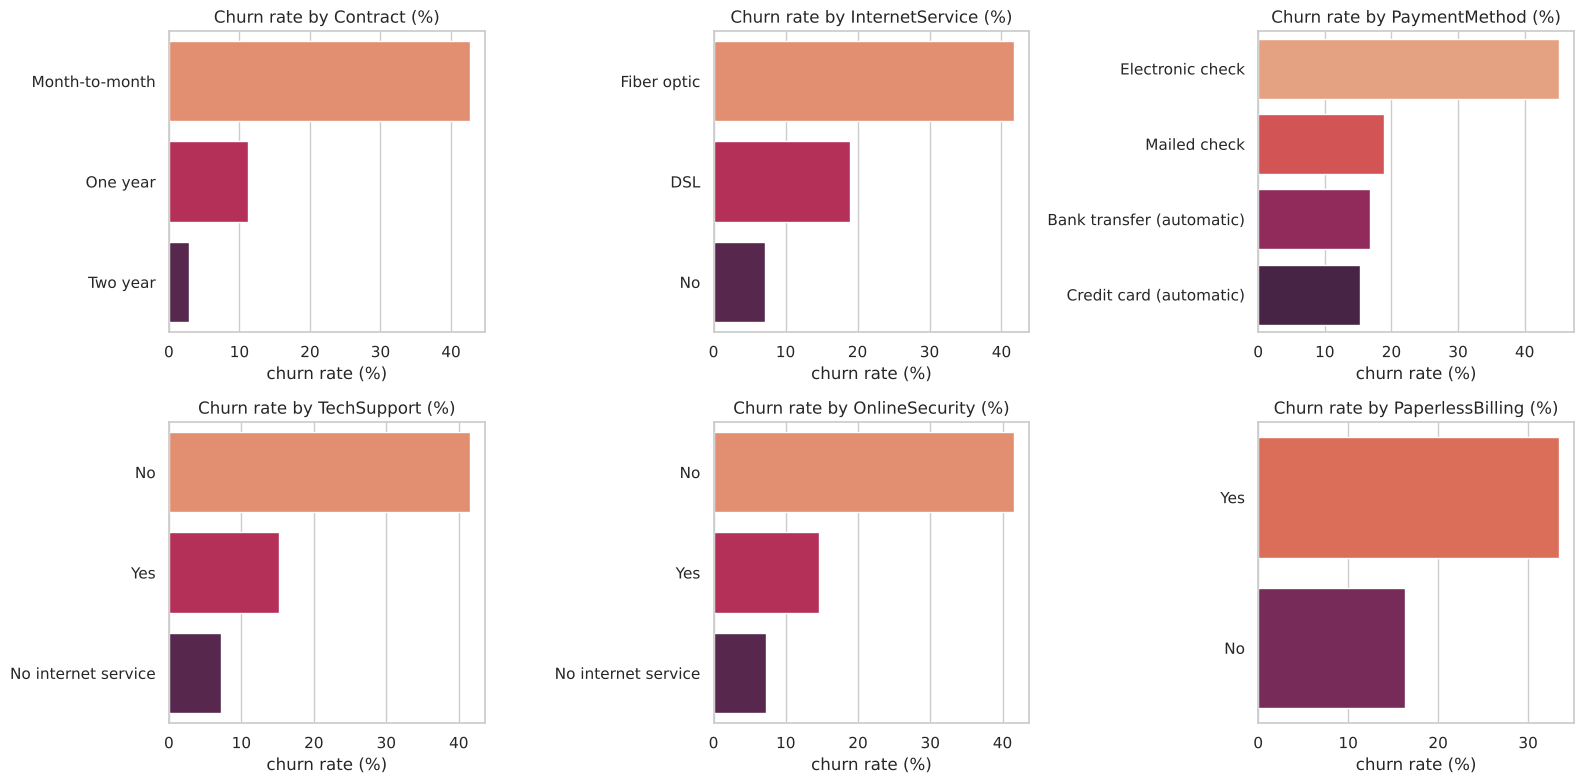

In [8]:
cats = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cats):
    rates = df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rates.values, y=rates.index, hue=rates.index, palette="rocket_r", legend=False, ax=ax)
    ax.set_title(f"Churn rate by {col} (%)"); ax.set_xlabel("churn rate (%)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(RESULTS / "churn_by_category.png", dpi=150); plt.show()

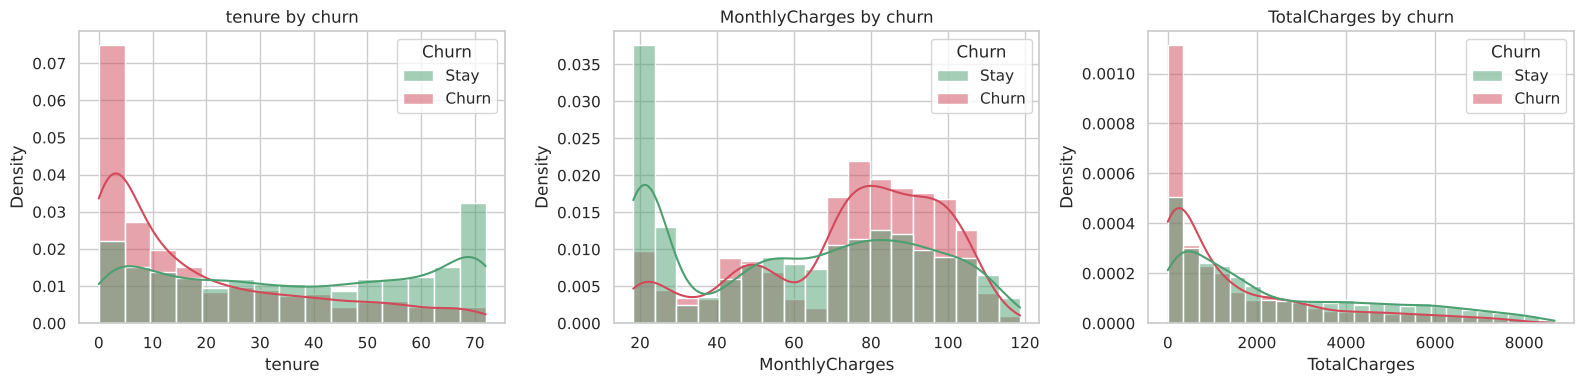

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue=df[TARGET].map({0: "Stay", 1: "Churn"}), kde=True, stat="density",
                 common_norm=False, palette=["#4C9F70", "#D1495B"], ax=ax)
    ax.set_title(f"{col} by churn")
plt.tight_layout(); plt.savefig(RESULTS / "numeric_distributions.png", dpi=150); plt.show()

**Findings.** Churn is concentrated in month-to-month contracts, fibre-optic internet, electronic-check payment, customers without tech support/online security, and **new customers (low tenure)**.

## 8. Feature engineering
Two extra features are created: `AvgMonthlySpend` (total paid ÷ months) and `NumServices` (count of optional services). They are computed row-by-row from the same customer, so they cannot leak information between train and test.

In [10]:
data = add_features(df)
X = data.drop(columns=TARGET)
y = data[TARGET]
numeric_cols, categorical_cols = split_columns(X)
print("Numeric:", numeric_cols)
print("Categorical (one-hot encoded):", categorical_cols)

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend', 'NumServices']
Categorical (one-hot encoded): ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 9–10. Train / test split and categorical encoding (`OneHotEncoder`)
The split is stratified so both parts keep the same churn rate. The encoder lives inside each pipeline, so it learns categories from training data only.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, f"(churn {y_train.mean():.1%})", "| Test:", X_test.shape, f"(churn {y_test.mean():.1%})")

Train: (5616, 21) (churn 26.4%) | Test: (1405, 21) (churn 26.5%)


## 11. Handling class imbalance
Only about a quarter of customers churn, so a model predicting “everyone stays” would score ~73 % accuracy and be useless. Two remedies are used:

* **Class weighting** — `class_weight="balanced_subsample"` for Random Forest, `scale_pos_weight = negatives / positives` for XGBoost.
* **SMOTE** — synthetic minority examples, applied **only inside the training folds** through an `imblearn` pipeline (never before the split).

In [12]:
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
scale_pos_weight = neg / pos
print(f"Training negatives: {neg} | positives: {pos} | scale_pos_weight = {scale_pos_weight:.3f}")
baseline_acc = neg / (neg + pos)
print(f"Accuracy of a naive 'always stay' model: {baseline_acc:.3f}")

Training negatives: 4131 | positives: 1485 | scale_pos_weight = 2.782
Accuracy of a naive 'always stay' model: 0.736


## 12–13. Define the models

In [13]:
rf = Pipeline([
    ("pre", build_preprocessor(X_train)),
    ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                     random_state=RANDOM_STATE, n_jobs=-1)),
])
xgb = Pipeline([
    ("pre", build_preprocessor(X_train, scale_numeric=False)),
    ("model", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                            scale_pos_weight=scale_pos_weight, eval_metric="logloss",
                            random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_smote = ImbPipeline([
    ("pre", build_preprocessor(X_train)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
])
baseline_models = {"Random Forest (class weights)": rf, "XGBoost (scale_pos_weight)": xgb, "Random Forest + SMOTE": rf_smote}
print(list(baseline_models))

['Random Forest (class weights)', 'XGBoost (scale_pos_weight)', 'Random Forest + SMOTE']


## 14. Cross-validation — model stability (training data only)

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision"}
cv_rows = []
for name, model in baseline_models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({"Model": name, **{f"{k} (mean)": res[f"test_{k}"].mean() for k in scoring},
                    "roc_auc (std)": res["test_roc_auc"].std()})
cv_df = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_df

,roc_auc (mean),f1 (mean),recall (mean),precision (mean),roc_auc (std)
Model,,,,,
Random Forest (class weights),0.8272,0.5446,0.4741,0.6404,0.0156
XGBoost (scale_pos_weight),0.8415,0.6306,0.7636,0.5372,0.0188
Random Forest + SMOTE,0.8244,0.5846,0.5710,0.5992,0.0167


## 15. Hyper-parameter tuning (`RandomizedSearchCV`, scoring = ROC-AUC, 5-fold CV on the training set)

In [15]:
rf_space = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [6, 8, 10, 14, None],
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__max_features": ["sqrt", 0.3, 0.5],
}
xgb_space = {
    "model__n_estimators": [150, 250, 350, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__reg_lambda": [1, 3, 10],
}
rf_search = RandomizedSearchCV(rf, rf_space, n_iter=15, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
xgb_search = RandomizedSearchCV(xgb, xgb_space, n_iter=25, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
rf_search.fit(X_train, y_train)
xgb_search.fit(X_train, y_train)
print(f"Random Forest best CV ROC-AUC: {rf_search.best_score_:.4f}\n  {rf_search.best_params_}")
print(f"XGBoost       best CV ROC-AUC: {xgb_search.best_score_:.4f}\n  {xgb_search.best_params_}")

Random Forest best CV ROC-AUC: 0.8485
  {'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 8}
XGBoost       best CV ROC-AUC: 0.8500
  {'model__subsample': 0.7, 'model__reg_lambda': 3, 'model__n_estimators': 350, 'model__min_child_weight': 3, 'model__max_depth': 4, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.8}


The three candidate models are now fitted on the full training set (the untuned SMOTE model is kept as a comparison for the imbalance strategy).

In [16]:
final_models = {
    "Random Forest (tuned)": rf_search.best_estimator_,
    "XGBoost (tuned)": xgb_search.best_estimator_,
    "Random Forest + SMOTE": rf_smote.fit(X_train, y_train),
}
cv_scores = {"Random Forest (tuned)": rf_search.best_score_, "XGBoost (tuned)": xgb_search.best_score_,
             "Random Forest + SMOTE": cv_df.loc["Random Forest + SMOTE", "roc_auc (mean)"]}
best_name = max(["Random Forest (tuned)", "XGBoost (tuned)"], key=cv_scores.get)   # chosen by CV, not by the test set
best_model = final_models[best_name]
print("Best tuned model by cross-validated ROC-AUC:", best_name)

Best tuned model by cross-validated ROC-AUC: XGBoost (tuned)


## 16. Evaluation on the untouched test set

In [17]:
rows, probas, preds = [], {}, {}
for name, model in final_models.items():
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name], preds[name] = p, pred
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p)})
results_df = pd.DataFrame(rows).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest (tuned),0.7601,0.5325,0.7715,0.6301,0.8433
XGBoost (tuned),0.7573,0.5279,0.7876,0.6321,0.8448
Random Forest + SMOTE,0.7758,0.5831,0.5376,0.5594,0.8154


In [18]:
target_met = results_df.loc[best_name, "ROC-AUC"] > 0.80
print(f"{best_name}: test ROC-AUC = {results_df.loc[best_name, 'ROC-AUC']:.4f} -> task-pack target (> 0.80) met: {target_met}")
print()
print(classification_report(y_test, preds[best_name], target_names=["Stay", "Churn"], digits=3))

XGBoost (tuned): test ROC-AUC = 0.8448 -> task-pack target (> 0.80) met: True

              precision    recall  f1-score   support

        Stay      0.907     0.746     0.819      1033
       Churn      0.528     0.788     0.632       372

    accuracy                          0.757      1405
   macro avg      0.717     0.767     0.726      1405
weighted avg      0.807     0.757     0.769      1405



## 17. ROC curves and precision–recall curves

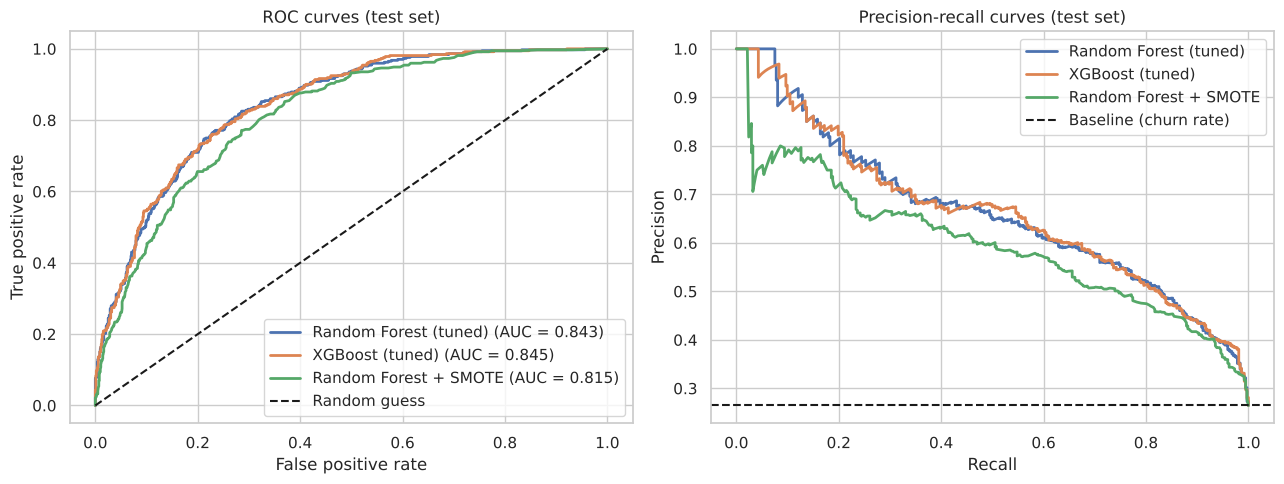

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rec, prec, lw=2, label=name)
ax[0].plot([0, 1], [0, 1], "k--", label="Random guess"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves (test set)"); ax[0].legend(loc="lower right")
ax[1].axhline(y_test.mean(), color="k", ls="--", label="Baseline (churn rate)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall curves (test set)"); ax[1].legend()
plt.tight_layout(); plt.savefig(RESULTS / "roc_curve.png", dpi=150); plt.show()

## 18. Confusion matrices

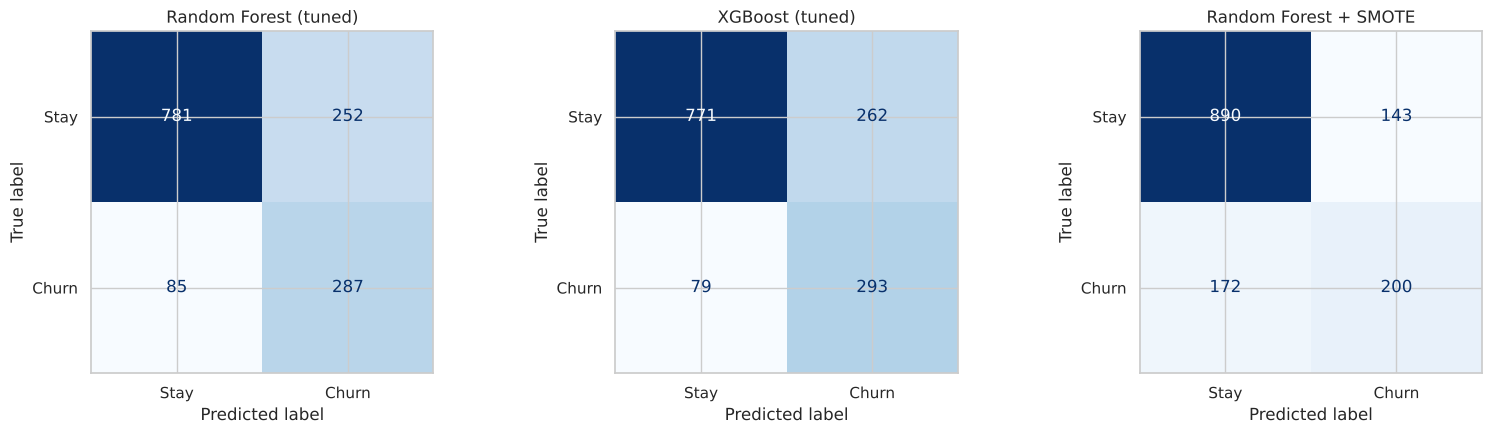

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Churn"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.savefig(RESULTS / "confusion_matrix.png", dpi=150); plt.show()

## 19. Model comparison

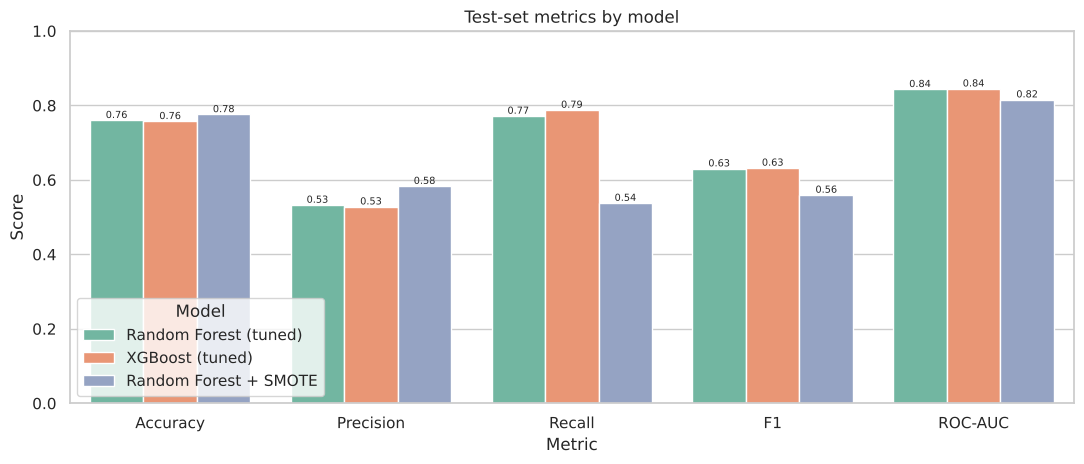

In [21]:
plot_df = results_df.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(11, 4.8))
ax = sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="Set2")
ax.set_ylim(0, 1.0); ax.set_title("Test-set metrics by model")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig(RESULTS / "model_comparison.png", dpi=150); plt.show()

## 20. Feature importance — top 10 drivers of churn

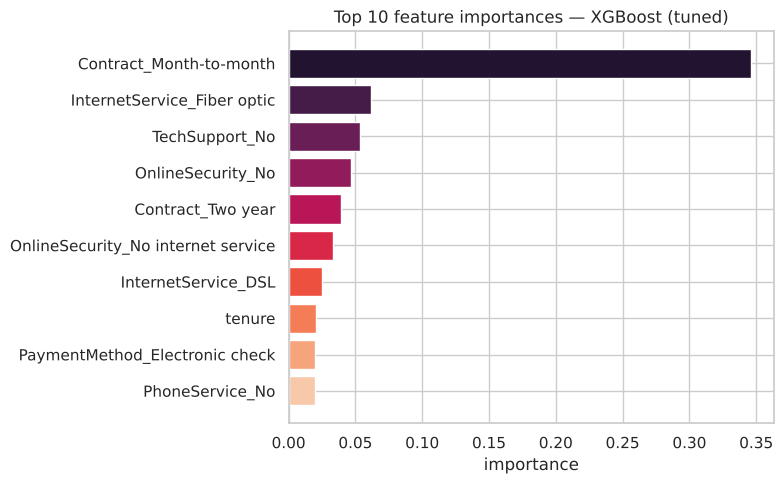

Contract_Month-to-month               0.3460
InternetService_Fiber optic           0.0613
TechSupport_No                        0.0535
OnlineSecurity_No                     0.0464
Contract_Two year                     0.0394
OnlineSecurity_No internet service    0.0334
InternetService_DSL                   0.0252
tenure                                0.0208
PaymentMethod_Electronic check        0.0199
PhoneService_No                       0.0196


In [22]:
pre = best_model.named_steps["pre"]
names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
imp = pd.Series(best_model.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
top10 = imp.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top10.index, top10.values, color=sns.color_palette("rocket_r", 10))
plt.title(f"Top 10 feature importances — {best_name}"); plt.xlabel("importance")
plt.tight_layout(); plt.savefig(RESULTS / "feature_importance.png", dpi=150); plt.show()
print(imp.head(10).round(4).to_string())

Feature importance shows what the model *uses*; it does not prove causation (for example, a customer on a month-to-month contract is not necessarily leaving *because of* the contract).

## 21. Prediction function for a new customer

In [23]:
new_customer = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No", "tenure": 3,
    "PhoneService": "Yes", "MultipleLines": "No", "InternetService": "Fiber optic", "OnlineSecurity": "No",
    "OnlineBackup": "No", "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes", "StreamingMovies": "Yes",
    "Contract": "Month-to-month", "PaperlessBilling": "Yes", "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.5, "TotalCharges": "286.5",
}
loyal_customer = {**new_customer, "tenure": 60, "Contract": "Two year", "OnlineSecurity": "Yes", "TechSupport": "Yes",
                  "PaymentMethod": "Credit card (automatic)", "MonthlyCharges": 70.0, "TotalCharges": "4200.0"}
print("New, month-to-month, fibre, no support ->", predict_churn(best_model, new_customer))
print("Long-term, two-year, with support      ->", predict_churn(best_model, loyal_customer))

New, month-to-month, fibre, no support -> {'churn_probability': 0.8708, 'prediction': 'Churn'}
Long-term, two-year, with support      -> {'churn_probability': 0.0815, 'prediction': 'Stay'}


## 22. Save models and metrics

In [24]:
joblib.dump(best_model, MODELS / "best_churn_model.joblib")
joblib.dump(final_models["Random Forest (tuned)"], MODELS / "random_forest.joblib")
joblib.dump(final_models["XGBoost (tuned)"], MODELS / "xgboost.joblib")
summary = {
    "rows_after_cleaning": int(len(df)), "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "churn_rate": round(float(y.mean()), 4), "best_model_by_cv": best_name,
    "cv_roc_auc": {k: round(float(v), 4) for k, v in cv_scores.items()},
    "best_params": {"random_forest": rf_search.best_params_, "xgboost": xgb_search.best_params_},
    "test_metrics": results_df.to_dict(orient="index"),
    "target_roc_auc_gt_0_80_met": bool(target_met),
    "top_features": imp.head(10).round(4).to_dict(),
}
(RESULTS / "metrics.json").write_text(json.dumps(summary, indent=2, default=str))
print("Saved models:", sorted(p.name for p in MODELS.iterdir()))

Saved models: ['best_churn_model.joblib', 'random_forest.joblib', 'xgboost.joblib']


## 23. Conclusions

In [25]:
print(results_df.to_string()); print()
print(f"Selected model: {best_name} | test ROC-AUC {results_df.loc[best_name, 'ROC-AUC']:.3f} | recall (churners found) {results_df.loc[best_name, 'Recall']:.3f}")
print("Top drivers:", ", ".join(imp.head(5).index))

                       Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                              
Random Forest (tuned)    0.7601     0.5325  0.7715  0.6301   0.8433
XGBoost (tuned)          0.7573     0.5279  0.7876  0.6321   0.8448
Random Forest + SMOTE    0.7758     0.5831  0.5376  0.5594   0.8154

Selected model: XGBoost (tuned) | test ROC-AUC 0.845 | recall (churners found) 0.788
Top drivers: Contract_Month-to-month, InternetService_Fiber optic, TechSupport_No, OnlineSecurity_No, Contract_Two year


**Limitations.** One public, static dataset; the 0.5 probability threshold is a default (a business would choose it from the cost of losing a customer vs. the cost of a retention offer); feature importance is not causal; the model has not been tested for drift or fairness, so it is **not** production-ready.
**Next steps.** Threshold optimisation using costs, probability calibration, SHAP explanations, and a temporal validation split.